In [10]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent
sys.path.append(str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from src.data import clean_download, compute_losses, check_prices
from src.risk_measures import hs_var_es

prices = clean_download("^GSPC", "2015-01-01")
print(check_prices(prices))
loss = compute_losses(prices)

{'missing': np.int64(0), 'non_positive': np.int64(0), 'high_below_low': np.int64(0), 'close_outside_range': np.int64(0), 'zero_range': np.int64(0), 'duplicate_dates': np.int64(0), 'unsorted': 0}


In [5]:
risk = hs_var_es(loss)
print(risk.dropna().head())
print(risk.dropna().describe())

                 var        es
Date                          
2015-12-31  0.028052  0.034201
2016-01-04  0.028052  0.034201
2016-01-05  0.028052  0.034201
2016-01-06  0.028052  0.034201
2016-01-07  0.028052  0.034201
               var           es
count  2717.000000  2717.000000
mean      0.029653     0.038401
std       0.014224     0.022116
min       0.013554     0.015873
25%       0.019994     0.025075
50%       0.027102     0.033277
75%       0.032631     0.041658
max       0.070064     0.102202


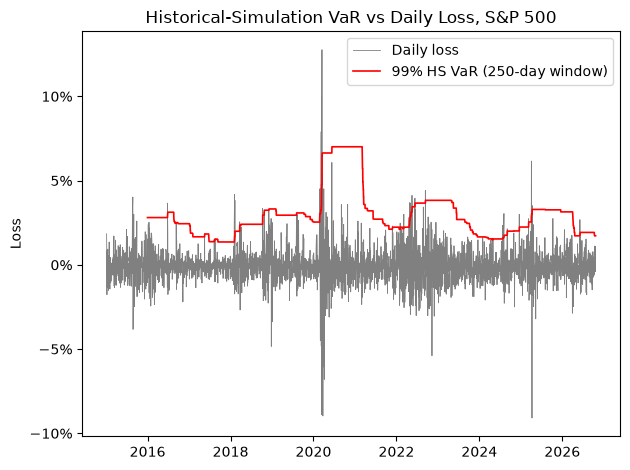

In [12]:
fig, ax = plt.subplots()
ax.plot(loss, label="Daily loss", color="grey", linewidth=0.6)
ax.plot(risk["var"], label="99% HS VaR (250-day window)", color="red", linewidth=1.2)
ax.set_title("Historical-Simulation VaR vs Daily Loss, S&P 500")
ax.set_ylabel("Loss")
ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.legend()

fig.tight_layout()
fig.savefig(ROOT / "results" / "hs_var.png", dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
risk = hs_var_es(loss)
bt = risk.join(loss).dropna()

,var,es,loss
Date,,,
2015-12-31,0.028052,0.034201,0.009456
2016-01-04,0.028052,0.034201,0.015422
2016-01-05,0.028052,0.034201,-0.002010
2016-01-06,0.028052,0.034201,0.013202
2016-01-07,0.028052,0.034201,0.023986
...,...,...,...
2026-10-15,0.017218,0.021734,-0.003249
2026-10-16,0.017218,0.021734,0.010987
2026-10-19,0.017218,0.021734,-0.004077


In [ ]:
hit = bt['loss'] > bt['var']
print(f'Days tested: {hit.index.size}')
print(f'Violations: {hit.sum()}')
print(f'Violation rate: {hit.mean()}')


Days tested: 2717
Violations: 43
Violation rate: 0.01582627898417372
